# Stochastic Optimal Control & Reinforcement Learning: from theory to code

Companion notebook to the interactive presentation. It runs top to bottom in **Google Colab** or Jupyter (needs only `numpy`, `matplotlib`, and `scipy`).

| Part | What you'll see |
|---|---|
| 0 | The slippery cliff world as a Markov decision process (MDP) |
| 1 | **Stochastic optimal control**: value iteration, and how risk changes the optimal route |
| 1b | Why the answer is a *policy*: open-loop plan vs. closed-loop policy (Monte Carlo) |
| 2 | **Reinforcement learning**: Q-learning rediscovers the optimal policy without the model |
| 3 | A business example: inventory control under random demand via dynamic programming |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Part 0: The world as an MDP

* **States** $s$: cells of a 5×8 grid. The bottom row between START and the goal is a cliff.
* **Actions** $a$: ↑ → ↓ ←
* **Transitions** $P(s'\mid s,a)$: the intended move with probability $1-p$, otherwise a slide to either side ($p/2$ each). Walls and edges block movement.
* **Rewards**: +10 at the goal, −10 at the cliff (both end the episode), and a small cost per step.
* **Objective**: maximize the expected discounted return $\mathbb{E}\left[\sum_t \gamma^t r_t\right]$.

In [2]:
class SlipperyCliff:
    ROWS, COLS = 5, 8
    MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # up, right, down, left
    ARROWS = ['↑', '→', '↓', '←']

    def __init__(self, slip=0.2, step_cost=-0.2):
        self.slip, self.step_cost = slip, step_cost
        self.n_states, self.n_actions = self.ROWS * self.COLS, 4
        self.start, self.goal = self.idx(4, 0), self.idx(4, 7)
        self.cliff = {self.idx(4, c) for c in range(1, 7)}

    idx = lambda self, r, c: r * self.COLS + c
    rc = lambda self, s: divmod(s, self.COLS)
    def terminal(self, s): return s == self.goal or s in self.cliff
    def reward(self, s2):  return 10.0 if s2 == self.goal else -10.0 if s2 in self.cliff else self.step_cost

    def move(self, s, a):
        r, c = self.rc(s); dr, dc = self.MOVES[a]
        r2, c2 = r + dr, c + dc
        return self.idx(r2, c2) if 0 <= r2 < self.ROWS and 0 <= c2 < self.COLS else s

    # ---- the MODEL: used by dynamic programming (Part 1) ----
    def P(self, s, a):
        p = self.slip
        return [(1 - p, self.move(s, a)), (p / 2, self.move(s, (a + 1) % 4)), (p / 2, self.move(s, (a + 3) % 4))]

    # ---- the SIMULATOR: the only thing Q-learning sees (Part 2) ----
    def reset(self):
        self.s = self.start
        return self.s
    def step(self, a):
        u = rng.random()
        d = a if u < 1 - self.slip else ((a + 1) % 4 if u < 1 - self.slip / 2 else (a + 3) % 4)
        s2 = self.move(self.s, d)
        self.s = s2
        return s2, self.reward(s2), self.terminal(s2)

env = SlipperyCliff()
print(f"{env.n_states} states, {env.n_actions} actions, slip p = {env.slip}")

40 states, 4 actions, slip p = 0.2


## Part 1: Stochastic optimal control with dynamic programming

Bellman's principle of optimality gives the **Bellman optimality equation**

$$V^*(s) = \max_a \sum_{s'} P(s'\mid s,a)\,\big[r(s') + \gamma V^*(s')\big]$$

**Value iteration** applies the right-hand side as an update to every state until the values stop changing. Because the update is a contraction for $\gamma<1$, it converges to $V^*$ from any starting point.

In [3]:
def q_from_v(env, V, gamma):
    Q = np.zeros((env.n_states, env.n_actions))
    for s in range(env.n_states):
        if env.terminal(s): continue
        for a in range(env.n_actions):
            Q[s, a] = sum(p * (env.reward(s2) + gamma * (0 if env.terminal(s2) else V[s2]))
                          for p, s2 in env.P(s, a))
    return Q

def value_iteration(env, gamma=0.95, tol=1e-8):
    V, history = np.zeros(env.n_states), []
    while True:
        Q = q_from_v(env, V, gamma)
        V_new = Q.max(axis=1)                       # Bellman optimality update
        delta = np.abs(V_new - V).max(); history.append(delta)
        V = V_new
        if delta < tol:
            return V, q_from_v(env, V, gamma).argmax(axis=1), history

def policy_evaluation(env, pi, gamma=0.95, tol=1e-10):
    """Exact value of a fixed policy (used to grade learned policies)."""
    V = np.zeros(env.n_states)
    while True:
        V_new = np.array([0 if env.terminal(s) else
                          sum(p * (env.reward(s2) + gamma * (0 if env.terminal(s2) else V[s2]))
                              for p, s2 in env.P(s, pi[s])) for s in range(env.n_states)])
        if np.abs(V_new - V).max() < tol: return V_new
        V = V_new

V_star, pi_star, hist = value_iteration(env)
print(f"Converged in {len(hist)} sweeps; V*(start) = {V_star[env.start]:.3f}")

Converged in 61 sweeps; V*(start) = 1.301


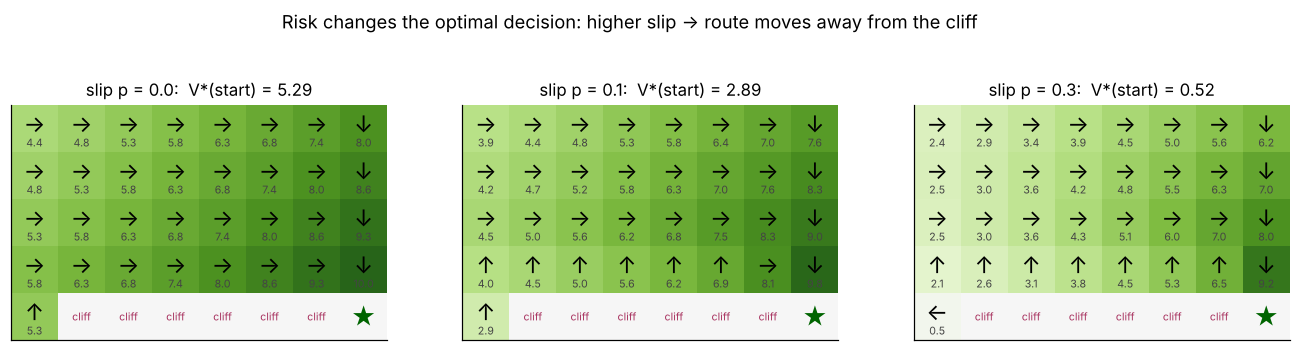

In [4]:
def plot_policy(ax, env, V, pi, title):
    grid = V.reshape(env.ROWS, env.COLS).copy()
    ax.imshow(grid, cmap="PiYG", vmin=-10, vmax=10)
    for s in range(env.n_states):
        r, c = env.rc(s)
        if s == env.goal: ax.text(c, r, "★", ha="center", va="center", fontsize=16, color="darkgreen")
        elif s in env.cliff: ax.text(c, r, "cliff", ha="center", va="center", fontsize=7, color="#a8325f")
        else:
            ax.text(c, r - 0.1, env.ARROWS[pi[s]], ha="center", va="center", fontsize=15)
            ax.text(c, r + 0.3, f"{V[s]:.1f}", ha="center", va="center", fontsize=7, color="#444")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, p in zip(axes, [0.0, 0.1, 0.3]):
    e = SlipperyCliff(slip=p)
    V, pi, _ = value_iteration(e)
    plot_policy(ax, e, V, pi, f"slip p = {p}:  V*(start) = {V[e.start]:.2f}")
plt.suptitle("Risk changes the optimal decision: higher slip → route moves away from the cliff", y=1.03)
plt.show()

**Reading the plots:** with no slip, the optimal route hugs the cliff (it's the shortest path). As $p$ grows, the robot pays extra steps to stay safe. At $p=0.3$ the START cell even says **←**, pushing into the wall: moving ↑ risks sliding right into the cliff, while pushing left is safe and waits for a lucky slide upward.

### Part 1b: Why the answer is a policy, not a plan
An **open-loop** controller commits to a fixed action sequence (the shortest path, planned as if there were no slips). A **closed-loop** policy $\pi^*(s)$ re-decides after observing where it actually landed.

In [5]:
def simulate(env, n=10_000, policy=None, sequence=None, gamma=0.95, max_steps=200):
    outcomes = {"goal": 0, "cliff": 0, "lost": 0}; returns = []
    for _ in range(n):
        s, G, disc = env.reset(), 0.0, 1.0
        T = len(sequence) if sequence is not None else max_steps
        for t in range(T):
            a = sequence[t] if sequence is not None else policy[s]
            s, r, done = env.step(a); G += disc * r; disc *= gamma
            if done: break
        outcomes["goal" if s == env.goal else "cliff" if s in env.cliff else "lost"] += 1
        returns.append(G)
    return {k: v / n for k, v in outcomes.items()}, np.mean(returns)

# open-loop plan = deterministic shortest path computed with p = 0
_, pi_det, _ = value_iteration(SlipperyCliff(slip=0.0))
plan, s = [], env.start
while not env.terminal(s):
    plan.append(pi_det[s]); s = env.move(s, pi_det[s])

for name, kw in [("Open-loop plan", dict(sequence=plan)), ("Closed-loop π*", dict(policy=pi_star))]:
    out, avg = simulate(env, **kw)
    print(f"{name:16s} goal {out['goal']:6.1%}   cliff {out['cliff']:6.1%}   lost {out['lost']:6.1%}   avg return {avg:6.2f}")

Open-loop plan   goal  13.6%   cliff  56.2%   lost  30.1%   avg return  -4.89
Closed-loop π*   goal  88.9%   cliff  11.1%   lost   0.0%   avg return   1.30


## Part 2: Reinforcement learning with Q-learning

Now pretend we **don't know $P$**. The agent can only call `env.reset()` and `env.step(a)`. Q-learning replaces the expectation in the Bellman equation with a single sampled transition:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma \max_{a'} Q(s',a') - Q(s,a)}_{\text{TD error}}\Big]$$

* **ε-greedy exploration:** random action with probability ε, otherwise the greedy one.
* **Decaying step size** $\alpha_n = \alpha_0 \cdot 30/(30+n(s,a))$, which meets the Robbins–Monro conditions used in the convergence proof (Watkins & Dayan, 1992).

In [6]:
def q_learning(env, episodes=3000, alpha0=0.5, gamma=0.95, eps=0.1, eval_every=25):
    Q = np.zeros((env.n_states, env.n_actions)); N = np.zeros_like(Q)
    returns, evals = [], []
    for ep in range(1, episodes + 1):
        s, done, G, disc, t = env.reset(), False, 0.0, 1.0, 0
        while not done and t < 200:
            if rng.random() < eps: a = rng.integers(env.n_actions)              # explore
            else: a = rng.choice(np.flatnonzero(Q[s] == Q[s].max()))          # exploit (random tie-break)
            s2, r, done = env.step(a)                                          # one sample, no P
            target = r + gamma * Q[s2].max() * (not done)
            N[s, a] += 1
            Q[s, a] += alpha0 * 30 / (30 + N[s, a]) * (target - Q[s, a])
            G += disc * r; disc *= gamma; s = s2; t += 1
        returns.append(G)
        if ep % eval_every == 0:   # grade the greedy policy with the TRUE model (for plotting only)
            evals.append((ep, policy_evaluation(env, Q.argmax(axis=1), gamma)[env.start]))
    return Q, np.array(returns), np.array(evals)

Q, returns, evals = q_learning(env)
pi_rl = Q.argmax(axis=1)
nonterm = [s for s in range(env.n_states) if not env.terminal(s)]
Q_star = q_from_v(env, V_star, 0.95)
agree = np.mean([Q_star[s, pi_rl[s]] >= Q_star[s].max() - 1e-6 for s in nonterm])
print(f"Learned policy value V(start) = {evals[-1,1]:.3f}   vs   optimal V*(start) = {V_star[env.start]:.3f}")
print(f"States where the learned action is optimal: {agree:.0%}")

Learned policy value V(start) = 1.226   vs   optimal V*(start) = 1.301
States where the learned action is optimal: 85%


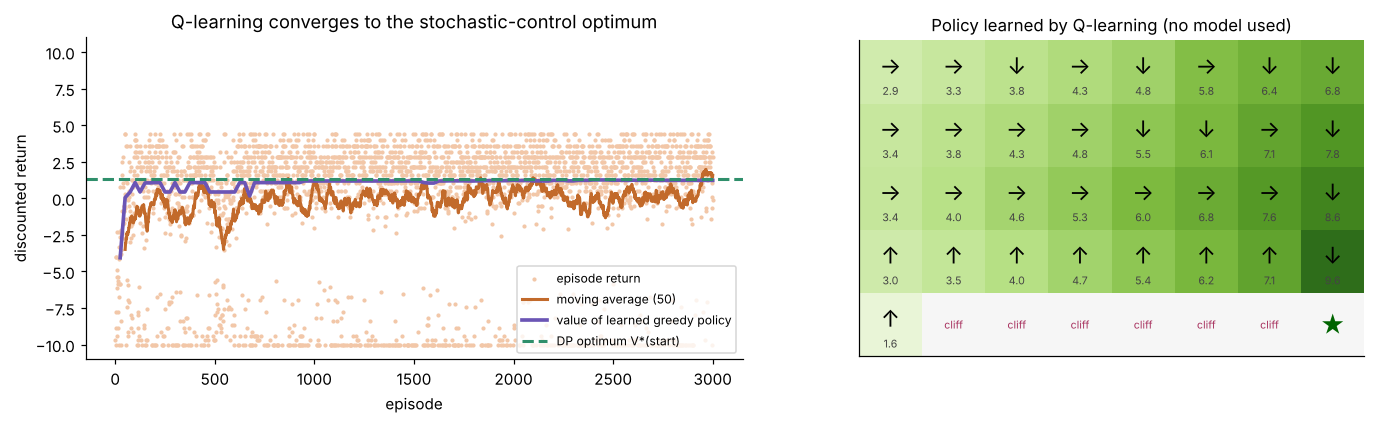

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ma = np.convolve(returns, np.ones(50) / 50, mode="valid")
ax1.scatter(np.arange(1, len(returns) + 1), returns, s=3, color="#f2c7a8", label="episode return")
ax1.plot(np.arange(50, len(returns) + 1), ma, color="#c26a2b", lw=2, label="moving average (50)")
ax1.plot(evals[:, 0], evals[:, 1], color="#6b55b5", lw=2.4, label="value of learned greedy policy")
ax1.axhline(V_star[env.start], ls="--", color="#2f8f6b", lw=2, label="DP optimum V*(start)")
ax1.set_xlabel("episode"); ax1.set_ylabel("discounted return"); ax1.set_ylim(-11, 11); ax1.legend(fontsize=8, loc="lower right")
ax1.set_title("Q-learning converges to the stochastic-control optimum")
plot_policy(ax2, env, Q.max(axis=1), pi_rl, "Policy learned by Q-learning (no model used)")
plt.show()

Exploring episodes (dots) stay below the optimum because the agent keeps taking random actions 10% of the time. That gap is the *price of learning*. The greedy policy it has learned (purple) approaches the DP answer from Part 1.

## Part 3: A business example of inventory control under random demand

A classic stochastic control problem in operations, solved by **finite-horizon (backward) dynamic programming**:

* State $x_t$: units on hand at the start of week $t$ (0 to 30)
* Control $u_t$: units to order (arrive immediately)
* Noise $w_t$: demand ~ Poisson(λ = 8); unmet demand is lost
* Cost per week: ordering $c\,u$ + holding $h\cdot$(leftover) + shortage penalty $b\cdot$(unmet demand)

$$J_t(x) = \min_u \; \mathbb{E}_w\big[c\,u + h\,(x+u-w)^+ + b\,(w-x-u)^+ + J_{t+1}\big((x+u-w)^+\big)\big]$$

Theory says the optimal policy is **base-stock (order-up-to)**: order enough to bring inventory up to a level $S_t$. Let's see if DP finds that structure on its own.

Order-up-to level S_t by week: [12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 11, 9]
Theory check — early weeks (leftovers carry over): Poisson quantile at b/(b+h)     = 12
Theory check — final week (newsvendor):             Poisson quantile at (b-c)/(b+h) = 9


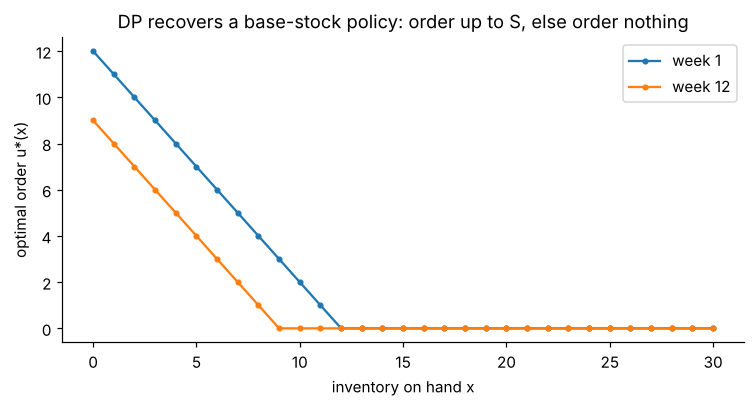

In [8]:
T, MAX_INV, LAM = 12, 30, 8
c, h, b = 2.0, 0.5, 6.0                     # order, holding, shortage cost per unit
w = np.arange(0, 40); pw = poisson.pmf(w, LAM); pw /= pw.sum()

J = np.zeros(MAX_INV + 1)                   # terminal cost J_T = 0
policy = np.zeros((T, MAX_INV + 1), dtype=int)
for t in reversed(range(T)):                # backward induction
    J_new = np.zeros_like(J)
    for x in range(MAX_INV + 1):
        best, best_u = np.inf, 0
        for u in range(MAX_INV - x + 1):
            y = x + u
            left = np.maximum(y - w, 0); short = np.maximum(w - y, 0)
            cost = c * u + np.sum(pw * (h * left + b * short + J[left]))
            if cost < best: best, best_u = cost, u
        J_new[x], policy[t, x] = best, best_u
    J = J_new

S = [int(policy[t, 0]) for t in range(T)]     # order-up-to level = order placed from empty
print("Order-up-to level S_t by week:", S)
print(f"Theory check — early weeks (leftovers carry over): Poisson quantile at b/(b+h)     = {poisson.ppf(b/(b+h), LAM):.0f}")
print(f"Theory check — final week (newsvendor):             Poisson quantile at (b-c)/(b+h) = {poisson.ppf((b-c)/(b+h), LAM):.0f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for t in [0, T - 1]:
    ax.plot(range(MAX_INV + 1), policy[t], marker="o", ms=3, label=f"week {t + 1}")
ax.set_xlabel("inventory on hand x"); ax.set_ylabel("optimal order u*(x)")
ax.set_title("DP recovers a base-stock policy: order up to S, else order nothing"); ax.legend()
plt.show()

The optimal order falls one-for-one with inventory until it hits zero: exactly an order-up-to policy, discovered by DP rather than assumed. The levels also match closed-form theory: in the final week, the single-period **newsvendor** quantile $(b-c)/(b+h)$; in earlier weeks, leftovers carry over (so ordering cost cancels) and the level rises to the $b/(b+h)$ quantile.

## Summary

| | Stochastic optimal control | Reinforcement learning |
|---|---|---|
| Needs | Model $P$, rewards | A simulator or data |
| Method | Dynamic programming (plan) | Sample-based updates (learn) |
| Here | `value_iteration`, inventory DP | `q_learning` |
| Result | Exact optimal policy | Converges to the same policy |

**References:** Bellman (1957) *Dynamic Programming* · Sutton & Barto (2018) *Reinforcement Learning: An Introduction* · Bertsekas (2019) *Reinforcement Learning and Optimal Control* · Watkins & Dayan (1992) "Q-learning", *Machine Learning* · Powell (2022) *Reinforcement Learning and Stochastic Optimization*.